# Step 32: Speed and size of the final models (review E15)
Time to predict ONE one-second window on a laptop CPU (median and 95th percentile) and the size of each model. Only the prediction stage is timed; computing the input features (OpenFace, eGeMAPS, w2v-BERT 2.0, VideoMAE) is not included. A prediction faster than 1000 ms keeps up with live data.
*This notebook only loads the saved results of `src/32_latency_size.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Speed and size (review E15): prediction time and size of each final model.
- **Needs the NoXi data?** No: it loads reports/latency_size.csv (made by src/32_latency_size.py).
- **Result / use:** Best model about 2 ms per one-second window (7.6 MB); Transformer 17 ms. The time to compute the input features was not measured.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

In [4]:
lt = pd.read_csv('reports/latency_size.csv')
print(lt[['model', 'parameters', 'size_mb', 'latency_ms_median', 'latency_ms_p95', 'windows_per_second', 'real_time_margin']].round(2).to_string(index=False))

                                         model  parameters  size_mb  latency_ms_median  latency_ms_p95  windows_per_second  real_time_margin
                             Linear Regression       798.0     0.01               0.02            0.02          1835207.67          48192.77
                     Random Forest (100 trees)         NaN   436.19               1.60            1.88            39556.11            626.39
                  XGBoost (300 trees, depth 6)         NaN     1.39               0.51            1.06           125640.32           1960.98
       ANN (512-256), 1 window of 797 features    540161.0     2.16               1.98            2.42             6269.69            505.60
Dense head, w2v-BERT + VideoMAE (2,432 inputs)    655873.0     2.62               2.01            2.55            16076.01            497.30
           Dense head + context (7,296 inputs)   1901057.0     7.60               2.16            2.80            11824.26            463.60
           Tr

**Chart.** Time per window (log scale) and model size.

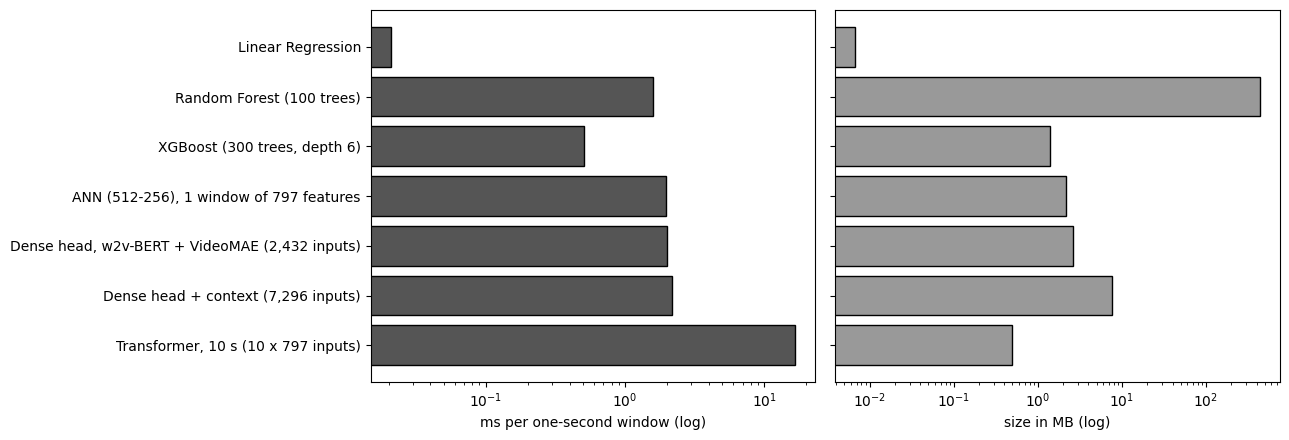

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(lt.model, lt.latency_ms_median, color='#555555', edgecolor='black'); ax[0].set_xscale('log'); ax[0].invert_yaxis(); ax[0].set_xlabel('ms per one-second window (log)')
ax[1].barh(lt.model, lt.size_mb, color='#999999', edgecolor='black'); ax[1].set_xscale('log'); ax[1].invert_yaxis(); ax[1].set_yticklabels([]); ax[1].set_xlabel('size in MB (log)')
plt.tight_layout(); plt.show()

**Reading.** The best model (dense head with context, 1.9 million parameters, 7.6 MB) needs about 2 ms per window, the Transformer about 17 ms, and a saved random forest takes 436 MB. All are far below one second, but the feature extraction time was not measured, so no full real-time claim is made.